# Presciptive Analysis of Heart Failure Dataset

In [40]:
# import required libraries
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)

In [41]:
# Load the dataset
datasetPath = Path("cardiac_failure")
dfPatientprofile = pd.read_csv(datasetPath / "10_PyMasters_Cleaned_Heartdata.csv")
dfPrescriptions = pd.read_csv(datasetPath / "10_PyMasters_Cleaned_Prescriptions.csv")

#### Question 1: Which heart-failure patients should be prioritized for enhanced monitoring at admission based on their visit history and current health condition?
##### - This analysis identifies patients who may need closer monitoring at admission by using their previous hospital visits and current health indicators.

In [42]:
# Select admission vital signs and outcome
vital_cols = ["pulse","respiration","systolic_blood_pressure", "diastolic_blood_pressure", "death_within_28_days"]

vitals = dfPatientprofile[vital_cols].dropna().copy()

# Create simple risk flags
vitals["high_pulse"] = vitals["pulse"] > 100
vitals["high_respiration"] = vitals["respiration"] > 20
vitals["low_systolic_bp"] = vitals["systolic_blood_pressure"] < 90

# Count number of abnormal vital signs
vitals["abnormal_vitals"] = (vitals["high_pulse"].astype(int)
    + vitals["high_respiration"].astype(int)
    + vitals["low_systolic_bp"].astype(int))

# Calculate mortality by number of abnormal vital signs
vital_risk = (
    vitals.groupby("abnormal_vitals")["death_within_28_days"]
    .agg(["count", "mean"])
    .reset_index()
)

vital_risk["mortality_rate_%"] = vital_risk["mean"] * 100
vital_risk.round(2)

,abnormal_vitals,count,mean,mortality_rate_%
0,0,1446,0.01,1.24
1,1,443,0.03,2.93
2,2,115,0.04,4.35
3,3,1,0.00,0.00


#### Insights : Patients having with multiple abnormal vital signs can be prioritized for enhanced monitoring during admission.

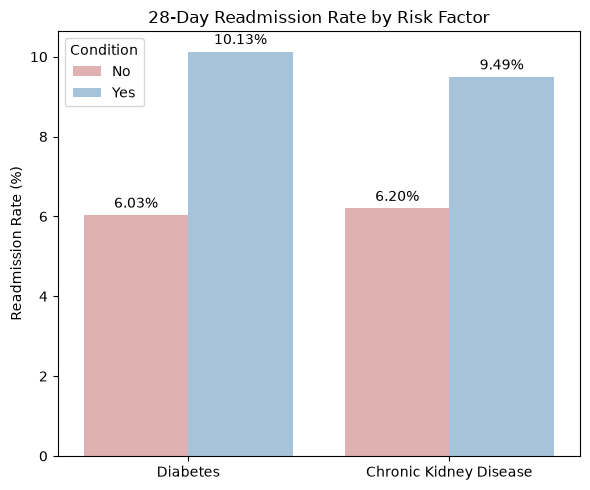

In [43]:
# Question 2: Which patients are at higher risk of 28-day readmission and should receive early follow-up after discharge?
# - This analysis identifies patients with a higher risk of 28-day readmission so that early follow-up can be prioritized after discharge.

# Select relevant variables
data = dfPatientprofile[
    [  "diabetes", "moderate_to_severe_chronic_kidney_disease", "re_admission_within_28_days" ]].dropna()

# Calculate readmission rate for each risk factor
diabetes = (
    data.groupby("diabetes")["re_admission_within_28_days"]
    .mean().reset_index())
diabetes["Risk Factor"] = "Diabetes"
diabetes["Group"] = diabetes["diabetes"].map({0: "No", 1: "Yes"})

ckd = (
    data.groupby("moderate_to_severe_chronic_kidney_disease")
    ["re_admission_within_28_days"]
    .mean()
    .reset_index()
)
ckd["Risk Factor"] = "Chronic Kidney Disease"
ckd["Group"] = ckd[   "moderate_to_severe_chronic_kidney_disease"].map({0: "No", 1: "Yes"})

# Combine the results
result = pd.concat([
    diabetes[["Risk Factor", "Group", "re_admission_within_28_days"]],
    ckd[["Risk Factor", "Group", "re_admission_within_28_days"]]
])

# Convert to percentage
result["readmission_rate_%"] = (
    result["re_admission_within_28_days"] * 100
)

# Create chart directly from the result dataframe
plt.figure(figsize=(6, 5))

ax = sns.barplot(
    data=result,
    x="Risk Factor",
    y="readmission_rate_%",
    hue="Group",
    palette = ["#E8A9A9", "#9CC4E4"]
)
# Add data labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3
    )
    
plt.title("28-Day Readmission Rate by Risk Factor")
plt.xlabel("")
plt.ylabel("Readmission Rate (%)")
plt.legend(title="Condition")

plt.tight_layout()
plt.show()

#### Question 3: Which demographic and heart-failure groups have higher readmission rates at 28 days, 3 months, and 6 months?
#### - This analysis compares readmission rates across age, gender, occupation, heart-failure type, and BMI groups at 28 days, 3 months, and 6 months to identify patient groups that may require more sustained follow-up after discharge.

In [44]:
# Select variables
data = dfPatientprofile[
    [
        "agecat",
        "gender",
        "occupation",
        "bmi",
        "type_of_heart_failure",
        "re_admission_within_28_days",
        "re_admission_within_3_months",
        "re_admission_within_6_months"
    ]
].dropna()

# Variables to compare
group_vars = [
    "agecat",
    "gender",
    "occupation",
    "type_of_heart_failure"
]

# Create BMI groups
data["BMI_group"] = pd.cut(
    data["bmi"],
    bins=[0, 18.5, 25, 30, np.inf],
    labels=["Underweight", "Normal", "Overweight", "Obese"]
)

group_vars.append("BMI_group")

# Calculate readmission rates for each group
results = []

for group in group_vars:
    grouped = (
        data.groupby(group, observed=True)[
            [
                "re_admission_within_28_days",
                "re_admission_within_3_months",
                "re_admission_within_6_months"
            ]
        ]
        .mean()
        .reset_index()
    )

    grouped["Group_Type"] = group

    grouped = grouped.rename(
        columns={
            group: "Group"
        }
    )

    results.append(grouped)

# Combine all results
result = pd.concat(results, ignore_index=True)

# Convert rates to percentages
result["28_day_%"] = result["re_admission_within_28_days"] * 100
result["3_month_%"] = result["re_admission_within_3_months"] * 100
result["6_month_%"] = result["re_admission_within_6_months"] * 100
# Clean presentation table

clean_result = result[
    [
        "Group_Type",
        "Group",
        "28_day_%",
        "3_month_%",
        "6_month_%"
    ]
].copy()

# Rename columns for presentation
clean_result.columns = [
    "Patient Characteristic",
    "Group",
    "28-Day Readmission (%)",
    "3-Month Readmission (%)",
    "6-Month Readmission (%)"
]

# Round percentages
clean_result[
    [
        "28-Day Readmission (%)",
        "3-Month Readmission (%)",
        "6-Month Readmission (%)"
    ]
] = clean_result[
    [
        "28-Day Readmission (%)",
        "3-Month Readmission (%)",
        "6-Month Readmission (%)"
    ]
].round(2)

# Display clean table
clean_result

,Patient Characteristic,Group,28-Day Readmission (%),3-Month Readmission (%),6-Month Readmission (%)
0,agecat,21-29,25.00,75.00,75.00
1,agecat,29-39,0.00,0.00,8.33
2,agecat,39-49,5.36,23.21,32.14
3,agecat,49-59,2.88,23.08,37.50
4,agecat,59-69,6.65,18.84,34.35
5,agecat,69-79,6.66,26.77,41.08
6,agecat,79-89,8.28,25.78,37.66
7,agecat,89-110,6.12,24.49,41.84
8,gender,Female,6.24,24.26,37.52
9,gender,Male,7.86,24.91,39.18


#### Insights : Readmission becomes higher over time. For example, patients aged 69–79 have readmission rates of 6.66% at 28 days, 26.77% at 3 months, and 41.08% at 6 months.

####  Patients with both types of heart failure also show higher readmission rates: 7.90% at 28 days, 27.20% at 3 months, and 41.96% at 6 months. These groups may need follow-up that continues beyond the first 28 days.

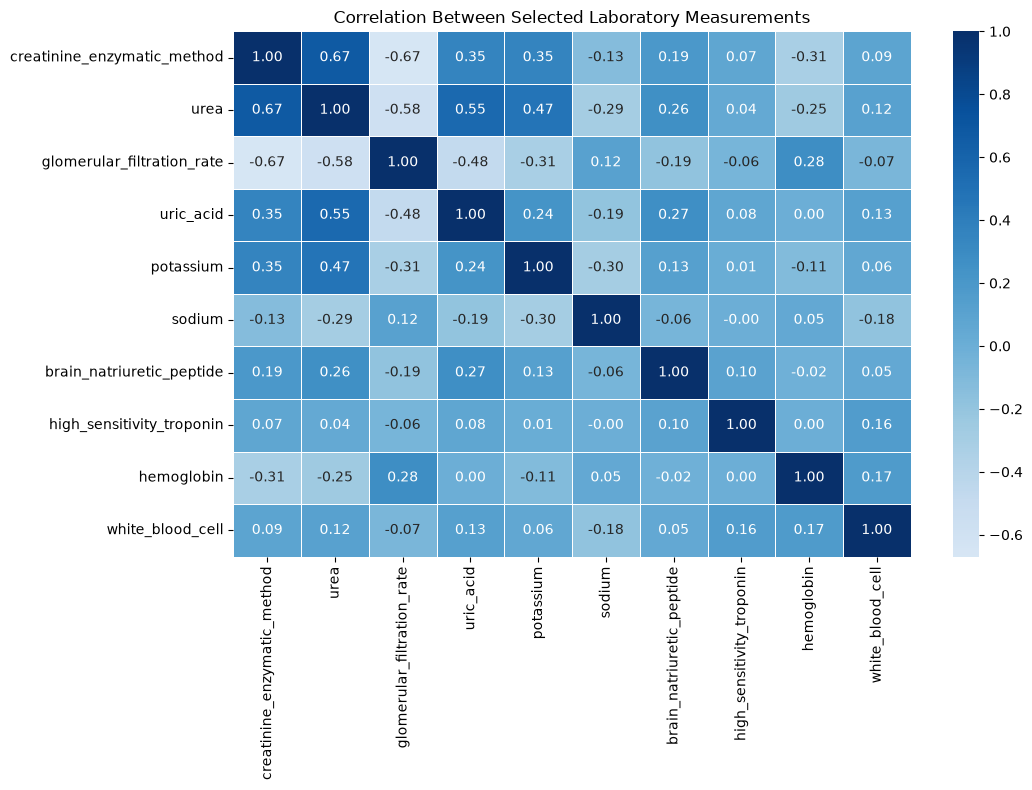

In [45]:
# Question 4: Which lab measurements show strong relationships with each other and may require closer monitoring together?

# Select important laboratory variables
lab_cols = [
    "creatinine_enzymatic_method", "urea", "glomerular_filtration_rate",
    "uric_acid", "potassium", "sodium", "brain_natriuretic_peptide",   "high_sensitivity_troponin",
    "hemoglobin",   "white_blood_cell"]

# Keep only selected lab data
lab_data = dfPatientprofile[lab_cols].apply(
    pd.to_numeric, errors="coerce"
)

# Calculate correlations
correlation_data = lab_data.corr()
# Create correlation heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_data,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Between Selected Laboratory Measurements")
plt.tight_layout()
plt.show()

##### - Insights: Kidney-related measurements show the strongest relationships. Creatinine and urea have a positive correlation of 0.67, while creatinine and GFR have a negative correlation of -0.67. This indicates that worsening kidney-related measurements tend to occur together.

Urea also has a moderate positive relationship with uric acid (0.55) and potassium (0.47). These relationships suggest that kidney-related laboratory values can be monitored together to identify changes that may require closer attention.

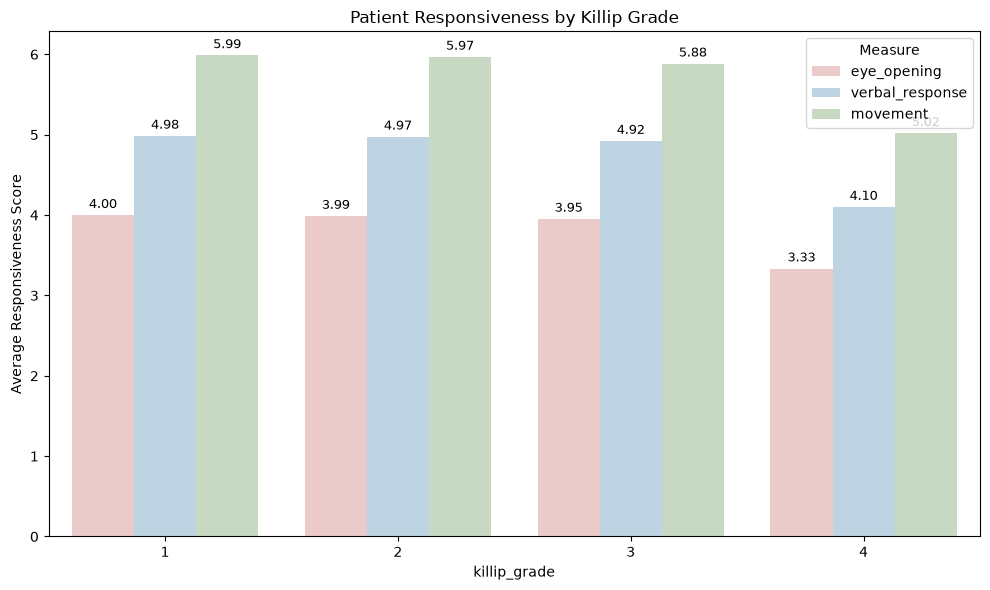

In [46]:
# Question 5: How does patient responsiveness at admission change with Killip grade?

# Select required variables
data = dfPatientprofile[
    [
        "killip_grade",
        "eye_opening",
        "verbal_response",
        "movement"
    ]
].dropna()

# Calculate average responsiveness for each Killip grade
result = (
    data.groupby("killip_grade")[
        [
            "eye_opening",
            "verbal_response",
            "movement"
        ]
    ]
    .agg(["count", "mean"])
)

# Prepare data for chart
chart_data = (
    data.groupby("killip_grade")[
        [
            "eye_opening",
            "verbal_response",
            "movement"
        ]
    ]
    .mean()
    .reset_index()
    .melt(
        id_vars="killip_grade",
        var_name="Responsiveness",
        value_name="Average Score"
    )
)

# Create chart
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=chart_data,
    x="killip_grade",
    y="Average Score",
    hue="Responsiveness",
    palette=["#F0C4C4", "#B8D5E8", "#C5DCC0"]
)

# Add data labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=3,
        fontsize=9
    )

plt.title("Patient Responsiveness by Killip Grade")
plt.xlabel("killip_grade")
plt.ylabel("Average Responsiveness Score")
plt.legend(title="Measure")

plt.tight_layout()
plt.show()

#### Insight: Patient responsiveness decreases as Killip grade increases, that patients with higher Killip grades, especially grade 4, may need closer monitoring of responsiveness during hospitalization.

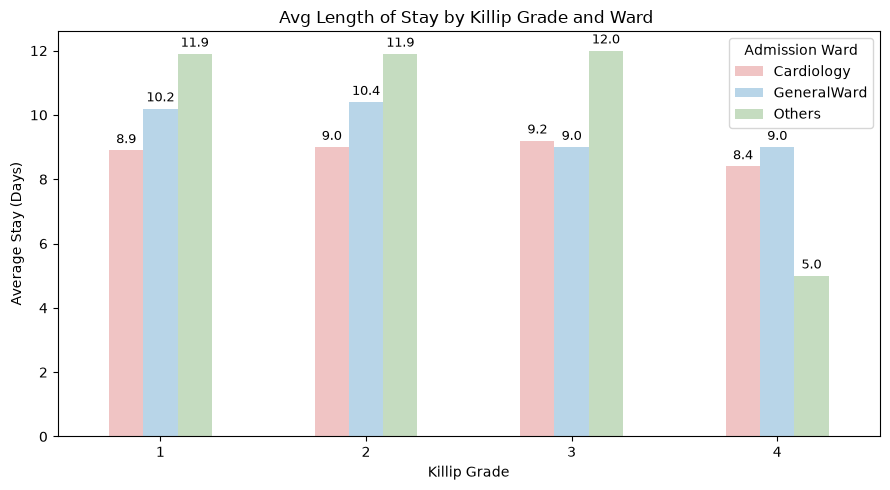

,avg_stay,patient_count,excess_vs_cardiology,bed_days_recoverable
admission_ward,,,,
Cardiology,9.0,1547,0.0,0.0
GeneralWard,10.0,265,1.0,265.0
ICU,13.9,15,4.9,74.0
Others,11.8,181,2.8,507.0


In [47]:
# ===== Question 6: Which wards have longer stays than expected for their patients' severity? 

severity_stay = (
    dfPatientprofile
    .groupby(["admission_ward", "killip_grade"])["dischargeday"]
    .mean()
    .unstack()
    .round(1)
)

overall_avg = dfPatientprofile.groupby("admission_ward")["dischargeday"].mean().round(1)
patient_counts = dfPatientprofile.groupby("admission_ward")["dischargeday"].count()
cardiology_avg = overall_avg["Cardiology"]

summary = pd.DataFrame({
    "avg_stay": overall_avg,
    "patient_count": patient_counts,
    "excess_vs_cardiology": (overall_avg - cardiology_avg).round(1)
})
summary["bed_days_recoverable"] = (summary["excess_vs_cardiology"] * summary["patient_count"]).clip(lower=0).round(0)

severity_stay_plot = severity_stay.drop("ICU")
ax = severity_stay_plot.T.plot(kind="bar", figsize=(9, 5), color=["#F0C4C4", "#B8D5E8", "#C5DCC0"])

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3, fontsize=9)
plt.title("Avg Length of Stay by Killip Grade and Ward ")
plt.xlabel("Killip Grade")
plt.ylabel("Average Stay (Days)")
plt.legend(title="Admission Ward")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

summary

### Insights : Patients with the same heart-failure severity (Killip grade) stay 3 days longer in the Others ward than in Cardiology — so the delay isnt about how sick they are, it's about the ward itself

brain_natriuretic_peptide: threshold=2016.8 | rate below=6.6000000000000005%, above=8.3%
high_sensitivity_troponin: threshold=0.2 | rate below=6.1%, above=12.0%
creatinine_enzymatic_method: threshold=139.9 | rate below=6.4%, above=9.6%


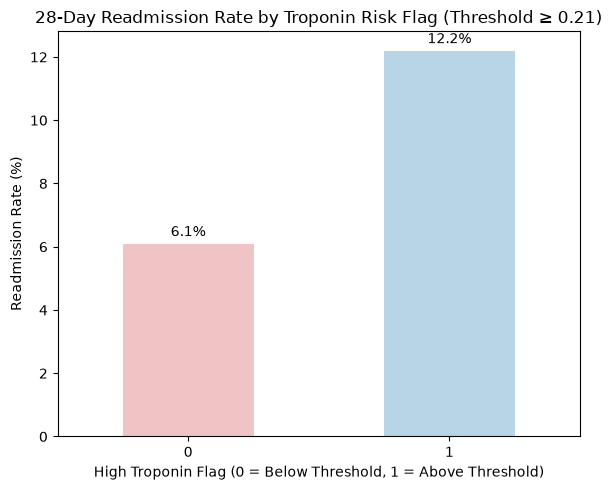

In [48]:
# Question :7 Which lab values at admission are associated with 28-day readmission, and what threshold should trigger early follow-up? 

# compared multiple labs - BNP, troponin, and creatinine to find the strongest signal
for lab, outcome in [("brain_natriuretic_peptide", "re_admission_within_28_days"),
                     ("high_sensitivity_troponin", "re_admission_within_28_days"),
                     ("creatinine_enzymatic_method", "re_admission_within_28_days")]:
    thresh = dfPatientprofile[dfPatientprofile[outcome] == 1][lab].quantile(0.75)
    flag = (dfPatientprofile[lab] >= thresh).astype(int)
    rate = dfPatientprofile.groupby(flag)[outcome].mean().round(3) * 100
    print(f"{lab}: threshold={thresh:.1f} | rate below={rate[0]}%, above={rate[1]}%")

# comparison across labs- shows troponin was the strongest signal
# Threshold = 75th percentile of troponin among patients who WERE readmitted within 28 days
threshold_trop = dfPatientprofile[dfPatientprofile["re_admission_within_28_days"] == 1]["high_sensitivity_troponin"].quantile(0.75).round(2)

# Defragment the DataFrame before adding the new column
dfPatientprofile = dfPatientprofile.copy()

dfPatientprofile["high_risk_flag"] = (dfPatientprofile["high_sensitivity_troponin"] >= threshold_trop).astype(int)

flag_readmission_rate = dfPatientprofile.groupby("high_risk_flag")["re_admission_within_28_days"].mean().round(3) * 100
flag_counts = dfPatientprofile["high_risk_flag"].value_counts()

# Chart
ax = flag_readmission_rate.plot(kind="bar", figsize=(6, 5), color=["#F0C4C4", "#B8D5E8"])
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3, fontsize=10)
plt.title(f"28-Day Readmission Rate by Troponin Risk Flag (Threshold ≥ {threshold_trop})")
plt.xlabel("High Troponin Flag (0 = Below Threshold, 1 = Above Threshold)")
plt.ylabel("Readmission Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


#### Insights : Patients with high-sensitivity troponin ≥ 0.21 at admission (279 of 2008 patients, ~14%) have a 12.2% 28-day readmission rate — roughly double the 6.1% rate for others. Recommend early follow-up  for this high-troponin patients before it leads to readmission.

#### Question 8: Do patients with multiple comorbidities (diabetes, CKD, liver disease, MI) have higher death and readmission risk, and how many comorbidities should trigger a dedicated care bundle at discharge?

                patient_count  death_6mo_rate  readmit_6mo_rate          care_bundle_action
comorbid_count                                                                             
0.0                      1123             2.0              34.8     Standard discharge care
1.0                       628             3.7              42.0     Standard discharge care
2.0                       232             3.9              45.3  Dedicated comorbidity care
3.0                        25            12.0              52.0  Dedicated comorbidity care


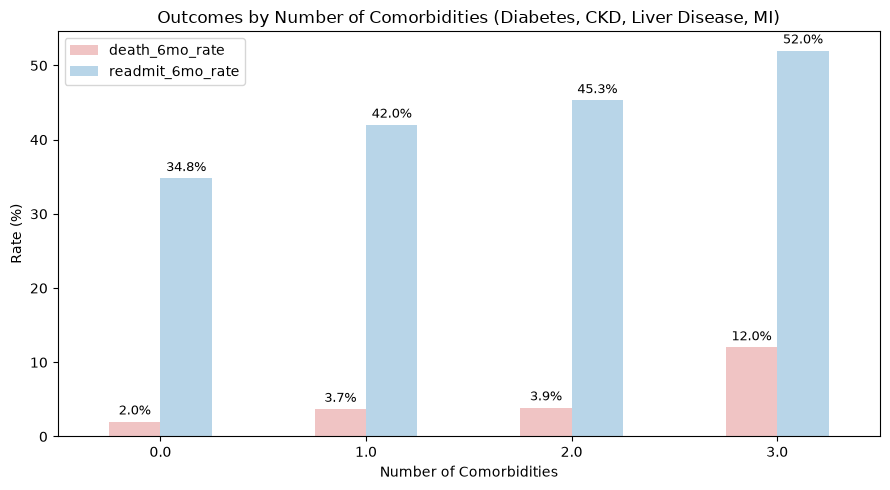

In [49]:
comorbid_cols = ["diabetes", "moderate_to_severe_chronic_kidney_disease", "liver_disease", "myocardial_infarction"]
dfPatientprofile["comorbid_count"] = dfPatientprofile[comorbid_cols].sum(axis=1)

comorbid_outcomes = dfPatientprofile.groupby("comorbid_count").agg(
    patient_count=("inpatient_number", "count"),
    death_6mo_rate=("death_within_6_months", "mean"),
    readmit_6mo_rate=("re_admission_within_6_months", "mean")
).round(3)
comorbid_outcomes[["death_6mo_rate", "readmit_6mo_rate"]] *= 100

comorbid_outcomes["care_bundle_action"] = comorbid_outcomes.index.map(
    lambda x: "Dedicated comorbidity care" if x >= 2 else "Standard discharge care"
)

pd.set_option("display.width", 1000)
print(comorbid_outcomes)

ax = comorbid_outcomes[["death_6mo_rate", "readmit_6mo_rate"]].plot(kind="bar", figsize=(9,5), color=["#F0C4C4", "#B8D5E8"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)
plt.title("Outcomes by Number of Comorbidities (Diabetes, CKD, Liver Disease, MI)")
plt.xlabel("Number of Comorbidities")
plt.ylabel("Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### - Insights: Patients with higher 3+ of comorbidities (diabetes, CKD, liver disease, MI) have a 12.0% 6-month death rate and 52.0% readmission rate higher than patients with none. Recommend enrolling patients with 2+ comorbidities in a dedicated care bundle (care coordinator, closer follow-up, medication review) at discharge.

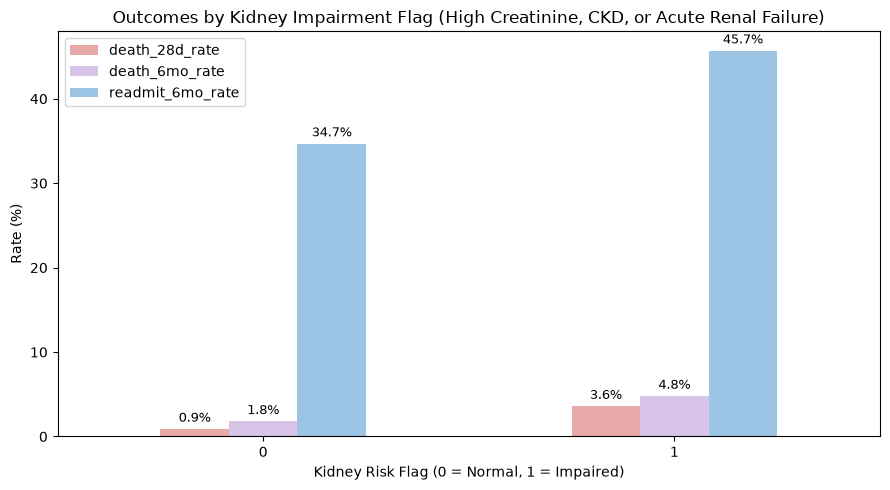

=== Main Result ===
                  patient_count  death_28d_rate  death_6mo_rate  readmit_6mo_rate  avg_stay
kidney_risk_flag                                                                           
0                          1321             0.9             1.8              34.7     8.690
1                           687             3.6             4.8              45.7    10.827


In [50]:
# Question 9: Do heart-failure patients with impaired kidney function have worse outcomes? 

creatinine_threshold = dfPatientprofile["creatinine_enzymatic_method"].quantile(0.75)

dfPatientprofile["kidney_risk_flag"] = (
    (dfPatientprofile["creatinine_enzymatic_method"] >= creatinine_threshold) |
    (dfPatientprofile["moderate_to_severe_chronic_kidney_disease"] == 1) |
    (dfPatientprofile["acute_renal_failure"] == 1)
).astype(int)

# Main result
kidney_outcomes = dfPatientprofile.groupby("kidney_risk_flag").agg(
    patient_count=("inpatient_number", "count"),
    death_28d_rate=("death_within_28_days", "mean"),
    death_6mo_rate=("death_within_6_months", "mean"),
    readmit_6mo_rate=("re_admission_within_6_months", "mean"),
    avg_stay=("dischargeday", "mean")
).round(3)
kidney_outcomes[["death_28d_rate", "death_6mo_rate", "readmit_6mo_rate"]] *= 100

ax = kidney_outcomes[["death_28d_rate", "death_6mo_rate", "readmit_6mo_rate"]].plot(kind="bar", figsize=(9,5), color=["#E8A9A9", "#D8C4E8", "#9CC4E4"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)
plt.title("Outcomes by Kidney Impairment Flag (High Creatinine, CKD, or Acute Renal Failure)")
plt.xlabel("Kidney Risk Flag (0 = Normal, 1 = Impaired)")
plt.ylabel("Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("=== Main Result ===")
print(kidney_outcomes)


#### Insights : Patients with poor kidney function have higher death risk and higher readmission rates than those with normal kidney function

           patient_count  death_6mo_rate  readmit_6mo_rate      recommended_destination
risk_tier                                                                              
High                 332             6.6              46.7           HealthcareFacility
Low                 1053             1.8              34.4    Home (standard discharge)
Medium               623             2.6              41.1  Home (with added follow-up)


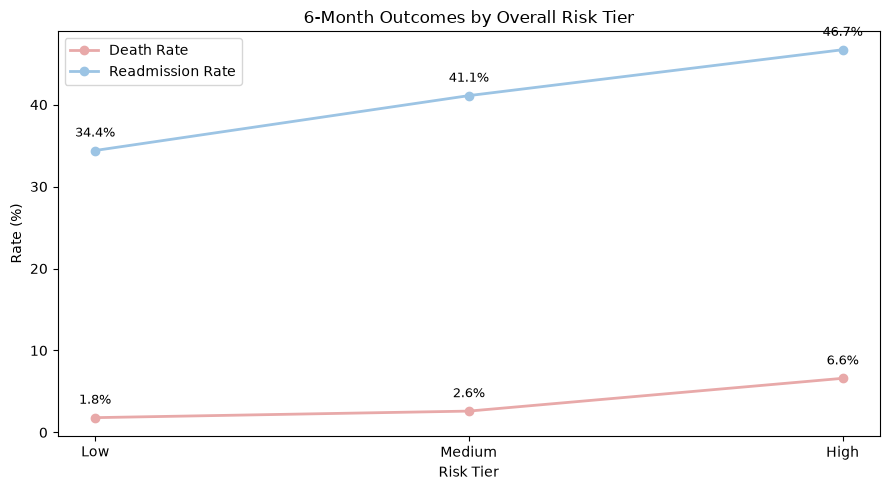

In [51]:
# Question 10: Based on a patient's combined risk profile (kidney function, vital signs, and comorbidity count) 
# at discharge, which destination — home, home-health, or rehab — should be recommended to reduce 6-month mortality and readmission

# Defragment the DataFrame before adding the new column
dfPatientprofile = dfPatientprofile.copy()

map_threshold = dfPatientprofile["map_value"].quantile(0.10)
pulse_threshold = dfPatientprofile["pulse"].quantile(0.90)

dfPatientprofile["vital_risk_flag"] = (
    (dfPatientprofile["map_value"] <= map_threshold) |
    (dfPatientprofile["pulse"] >= pulse_threshold)
).astype(int)

dfPatientprofile["overall_risk_score"] = (
    dfPatientprofile["kidney_risk_flag"] +
    dfPatientprofile["vital_risk_flag"] +
    (dfPatientprofile["comorbid_count"] >= 2).astype(int)
)


dfPatientprofile["risk_tier"] = dfPatientprofile["overall_risk_score"].map({
    0: "Low", 1: "Medium", 2: "High", 3: "High"
})

tier_outcomes = dfPatientprofile.groupby("risk_tier").agg(
    patient_count=("inpatient_number", "count"),
    death_6mo_rate=("death_within_6_months", "mean"),
    readmit_6mo_rate=("re_admission_within_6_months", "mean")
).round(3)
tier_outcomes[["death_6mo_rate", "readmit_6mo_rate"]] *= 100

tier_outcomes["recommended_destination"] = tier_outcomes.index.map({
    "Low": "Home (standard discharge)",
    "Medium": "Home (with added follow-up)",
    "High": "HealthcareFacility"
})

print(tier_outcomes)

tier_order = ["Low", "Medium", "High"]
tier_outcomes_ordered = tier_outcomes.reindex(tier_order).round(1)

fig, ax = plt.subplots(figsize=(9,5))
ax.plot(tier_outcomes_ordered.index, tier_outcomes_ordered["death_6mo_rate"], marker="o", linewidth=2, label="Death Rate", color="#E8A9A9")
ax.plot(tier_outcomes_ordered.index, tier_outcomes_ordered["readmit_6mo_rate"], marker="o", linewidth=2, label="Readmission Rate", color="#9CC4E4")

for i, tier in enumerate(tier_order):
    ax.annotate(f"{tier_outcomes_ordered['death_6mo_rate'][tier]:.1f}%",
                (i, tier_outcomes_ordered['death_6mo_rate'][tier]),
                textcoords="offset points", xytext=(0,10), ha='center', fontsize=9)
    ax.annotate(f"{tier_outcomes_ordered['readmit_6mo_rate'][tier]:.1f}%",
                (i, tier_outcomes_ordered['readmit_6mo_rate'][tier]),
                textcoords="offset points", xytext=(0,10), ha='center', fontsize=9)

plt.title("6-Month Outcomes by Overall Risk Tier")
plt.xlabel("Risk Tier")
plt.ylabel("Rate (%)")
plt.legend()
plt.tight_layout()
plt.show()


#### - Insights: Patients with more risk factors (poor kidney function, abnormal vitals, multiple comorbidities) have much higher death and readmission rates — High-risk patients are more likely at risk within 6 months than Low-risk patients. Recommend extended home-health monitoring for High-risk patients instead of standard discharge

#### Q11 How should the hospital's purchasing department allocate budget between standard and bariatric hospital beds based on patient physical profiles?

Insight - This analysis identifies the proportion of the patient population requiring specialized bariatric equipment by mapping height and weight distributions against obesity thresholds.

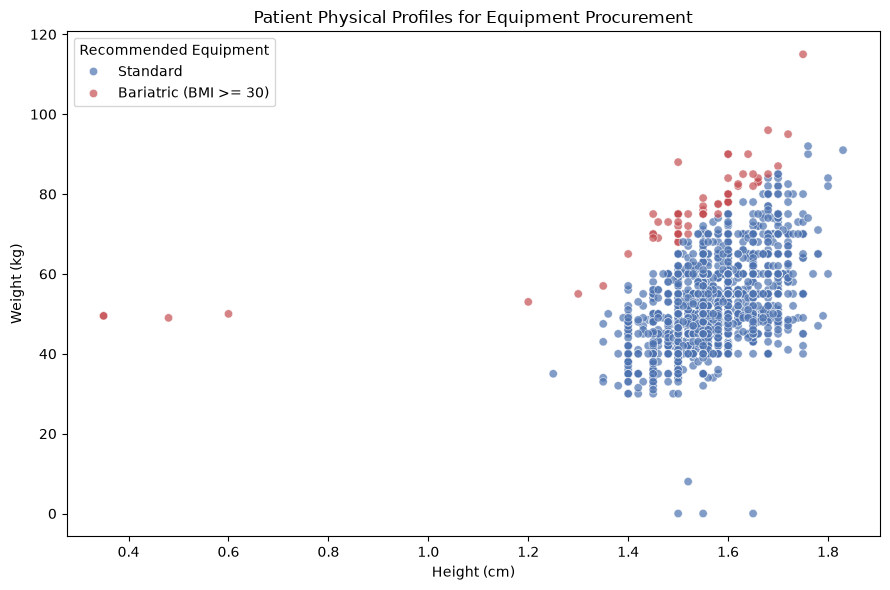

In [52]:
# Flag patients requiring bariatric equipment based on BMI threshold
dfPatientprofile['Equipment_Needs'] = dfPatientprofile['bmi'].apply(lambda x: 'Bariatric (BMI >= 30)' if x >= 30 else 'Standard')

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=dfPatientprofile, 
    x='height', 
    y='weight', 
    hue='Equipment_Needs', 
    palette={'Standard': '#4C72B0', 'Bariatric (BMI >= 30)': '#C44E52'}, 
    alpha=0.7
)
plt.title('Patient Physical Profiles for Equipment Procurement')
plt.xlabel('Height (cm)')
plt.ylabel('Weight (kg)')
plt.legend(title='Recommended Equipment')
plt.tight_layout()
plt.show()

The resulting scatter plot clusters patients by physical size, visually isolating the cohort with a BMI of 30 or higher. This visual clustering allows procurement teams to calculate the exact ratio of bariatric-rated beds, larger gowns, and heavy-duty mobility lifts needed versus standard ward equipment, ensuring capital is spent on actively utilized assets.

#### Q12 Which patients should be prioritized for immediate medication reconciliation by a clinical pharmacist based on their cognitive status and prescription volume?
Insight - This analysis highlights the intersection of cognitive impairment and polypharmacy, identifying vulnerable patients who require urgent review to mitigate drug interaction risks.

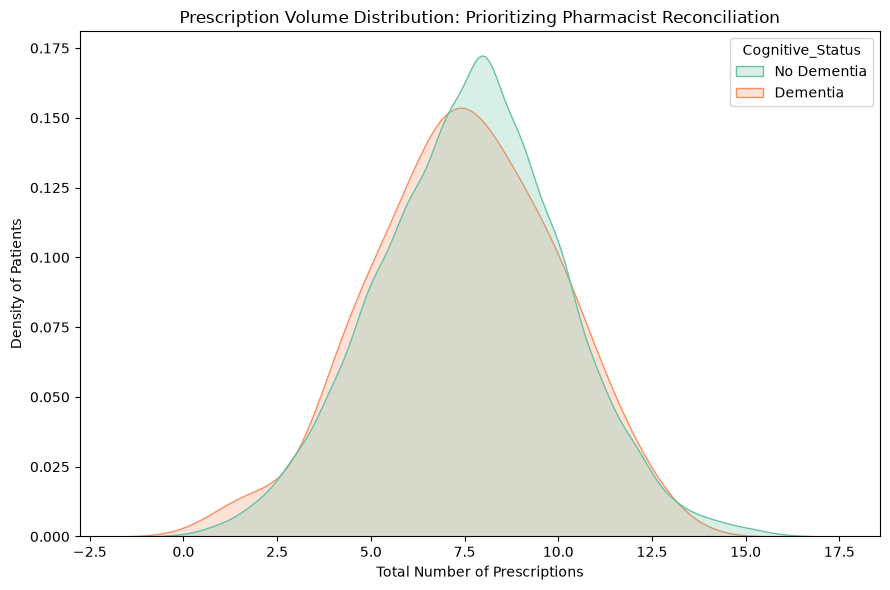

In [53]:


# Calculate total prescriptions per patient
rx_counts = dfPrescriptions.groupby('inpatient_number').size().reset_index(name='total_prescriptions')
df_merged = pd.merge(dfPatientprofile[['inpatient_number', 'dementia']], rx_counts, on='inpatient_number', how='left')
df_merged['total_prescriptions'] = df_merged['total_prescriptions'].fillna(0)
df_merged['Cognitive_Status'] = df_merged['dementia'].map({0: 'No Dementia', 1: 'Dementia'})

plt.figure(figsize=(9, 6))
sns.kdeplot(
    data=df_merged, 
    x='total_prescriptions', 
    hue='Cognitive_Status', 
    fill=True, 
    common_norm=False, 
    palette='Set2'
)
plt.title('Prescription Volume Distribution: Prioritizing Pharmacist Reconciliation')
plt.xlabel('Total Number of Prescriptions')
plt.ylabel('Density of Patients')
plt.tight_layout()
plt.show()

The density plot illustrates the volume of prescriptions given to patients, separated by cognitive status. A wider or right-skewed distribution for dementia patients visually flags a high-risk polypharmacy cohort. This insight justifies an operational policy that automatically routes files for dementia patients with above-average prescription counts directly to the top of the clinical pharmacist's daily review queue to prevent adherence failures and adverse drug events.

#### Q13: How should specialized cardiac care wings be partitioned and staffed to handle the distinct distribution of heart failure types across different demographic genders?
Insight - This analysis reveals the demographic breakdown of specific heart failure types, allowing administrators to tailor unit staffing, educational materials, and care pathways by gender prevalence.

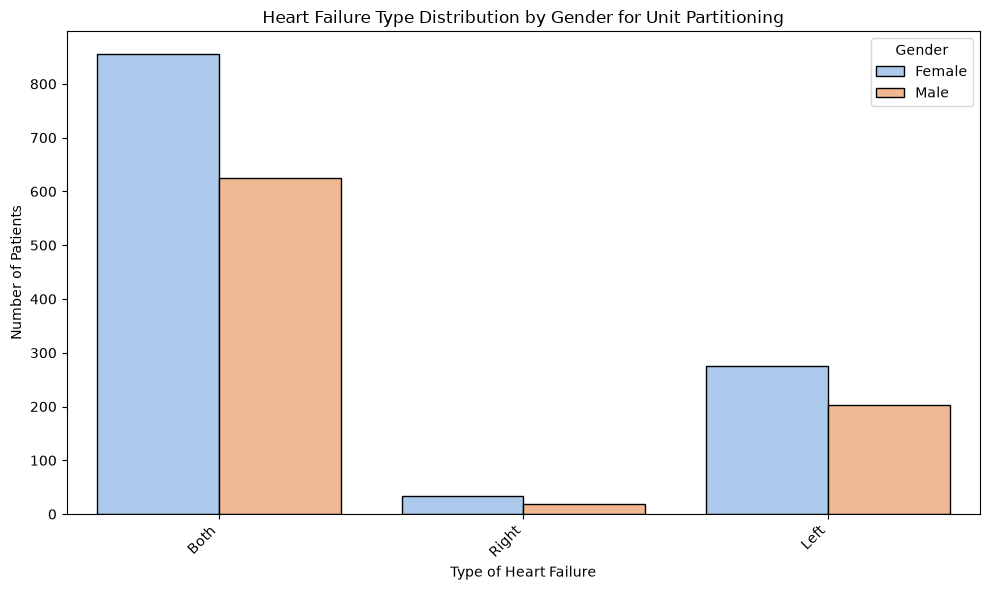

In [54]:
plt.figure(figsize=(10, 6))
sns.countplot(
    data=dfPatientprofile, 
    x='type_of_heart_failure', 
    hue='gender', 
    palette='pastel', 
    edgecolor='black'
)
plt.title('Heart Failure Type Distribution by Gender for Unit Partitioning')
plt.xlabel('Type of Heart Failure')
plt.ylabel('Number of Patients')
plt.legend(title='Gender')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

The grouped bar chart visualizes whether certain types of heart failure disproportionately affect male or female patients within the facility's population. If a stark gender imbalance exists for a specific failure type (e.g., HFpEF skewing heavily female), administrators can partition ward beds accordingly and ensure that the educational literature, nutritional plans, and specialized nursing training on those wings are highly tailored to the most prevalent demographic.

#### Q14: How should physical therapy and cardiac rehabilitation units be sized based on the volume of patients presenting in each NYHA cardiac function classification?
Insight - This analysis identifies the distribution of patients across NYHA classes to help allocate physical therapy resources and appropriately size rehabilitation units based on functional capacity.

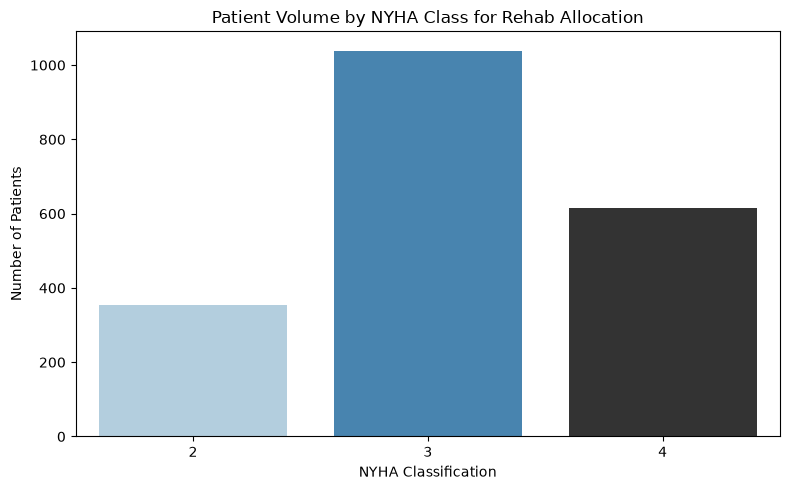

In [55]:
plt.figure(figsize=(8, 5))
sns.countplot(
    data=dfPatientprofile, 
    x='nyha_cardiac_function_classification', 
    palette='Blues_d',
    hue='nyha_cardiac_function_classification',legend=False,
    order=sorted(dfPatientprofile['nyha_cardiac_function_classification'].dropna().unique())
)
plt.title('Patient Volume by NYHA Class for Rehab Allocation')
plt.xlabel('NYHA Classification')
plt.ylabel('Number of Patients')
plt.tight_layout()
plt.show()

The bar chart reveals the bulk of the patient population's functional limitations. A high concentration in Class III or IV dictates a need for more intensive, bedside physical therapy and specialized mobility aids on the inpatient wards. Conversely, a skew toward Class I or II suggests resources can be safely shifted toward outpatient cardiac rehab programs and preventative strength training.

#### Q15 What BMI ranges characterize different levels of acute heart failure severity (Killip Grade) to help set thresholds for automatic dietary and weight-management consults?
Insight - This analysis identifies how BMI is distributed across different Killip Grades, pinpointing specific weight thresholds that correlate with acute heart failure severity to trigger automatic nutritional interventions.

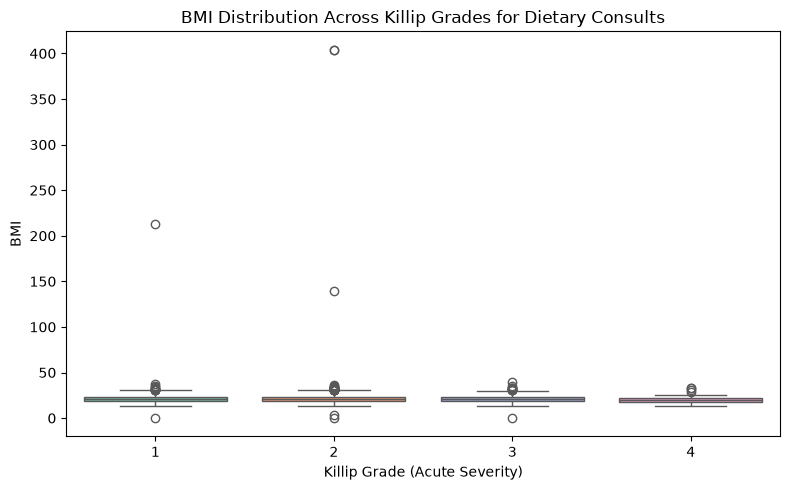

In [56]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=dfPatientprofile, 
    x='killip_grade', 
    y='bmi', 
    palette='Set2',
    hue='killip_grade',legend=False,
    order=sorted(dfPatientprofile['killip_grade'].dropna().unique())
)
plt.title('BMI Distribution Across Killip Grades for Dietary Consults')
plt.xlabel('Killip Grade (Acute Severity)')
plt.ylabel('BMI')
plt.tight_layout()
plt.show()

By examining the interquartile ranges of BMI across acute severity grades, clinical administrators can establish data-driven cutoff points. If severe acute presentations (Killip III/IV) consistently correlate with BMI outliers (underweight or severely obese), the hospital can configure its EHR to mandate automatic registered dietitian consults for any admission hitting those specific BMI markers.

#### Q16 How should the pharmacy distribute its stock of the top 5 most prescribed medications across different types of heart failure?
Expected insight - This analysis reveals the prescription volume of the top 5 medications stratified by heart failure type, guiding the pharmacy in budgeting and targeted inventory distribution across specialized cardiac wards.

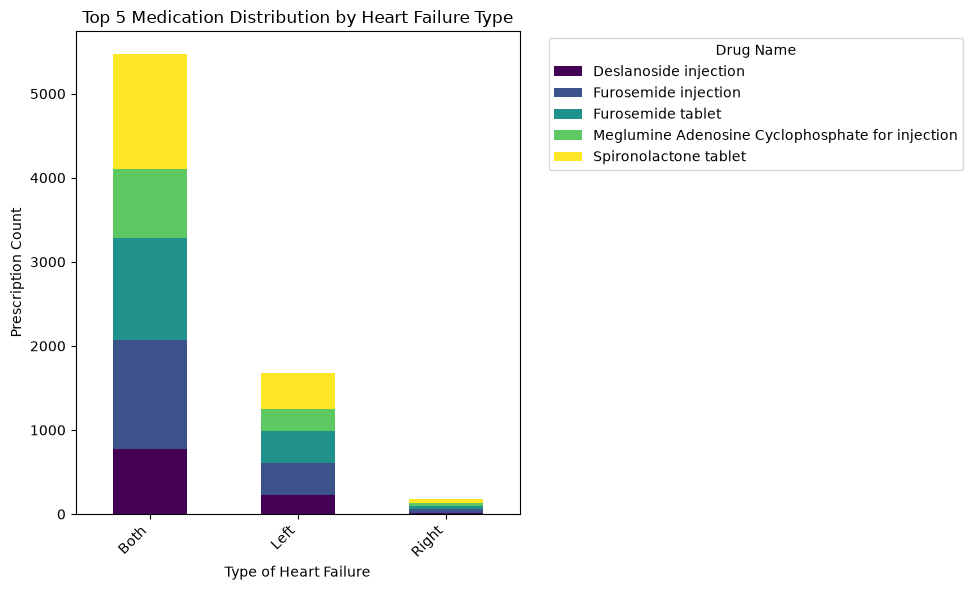

In [57]:
top_5_drugs = dfPrescriptions['drug_name'].value_counts().nlargest(5).index
df_rx_top = dfPrescriptions[dfPrescriptions['drug_name'].isin(top_5_drugs)]
merged_rx_hf = pd.merge(df_rx_top, dfPatientprofile[['inpatient_number', 'type_of_heart_failure']], on='inpatient_number')
crosstab_rx = pd.crosstab(merged_rx_hf['type_of_heart_failure'], merged_rx_hf['drug_name'])

crosstab_rx.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='viridis')
plt.title('Top 5 Medication Distribution by Heart Failure Type')
plt.xlabel('Type of Heart Failure')
plt.ylabel('Prescription Count')
plt.legend(title='Drug Name', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

The stacked bar chart exposes drug-to-disease dependencies. If a specific medication is overwhelmingly prescribed for one type of heart failure over another, the pharmacy can physical shift par levels of those drugs directly to the specific wings or floors that handle those patient profiles, minimizing delays in administration.

#### Q17 Which historical comorbidities most frequently co-occur in the patient population, indicating a need to form specific multi-disciplinary care teams?
Insight - This analysis maps the correlation between various historical comorbidities, highlighting the most common clinical intersections to justify the creation of targeted multi-disciplinary care teams (e.g., cardio-nephrology).

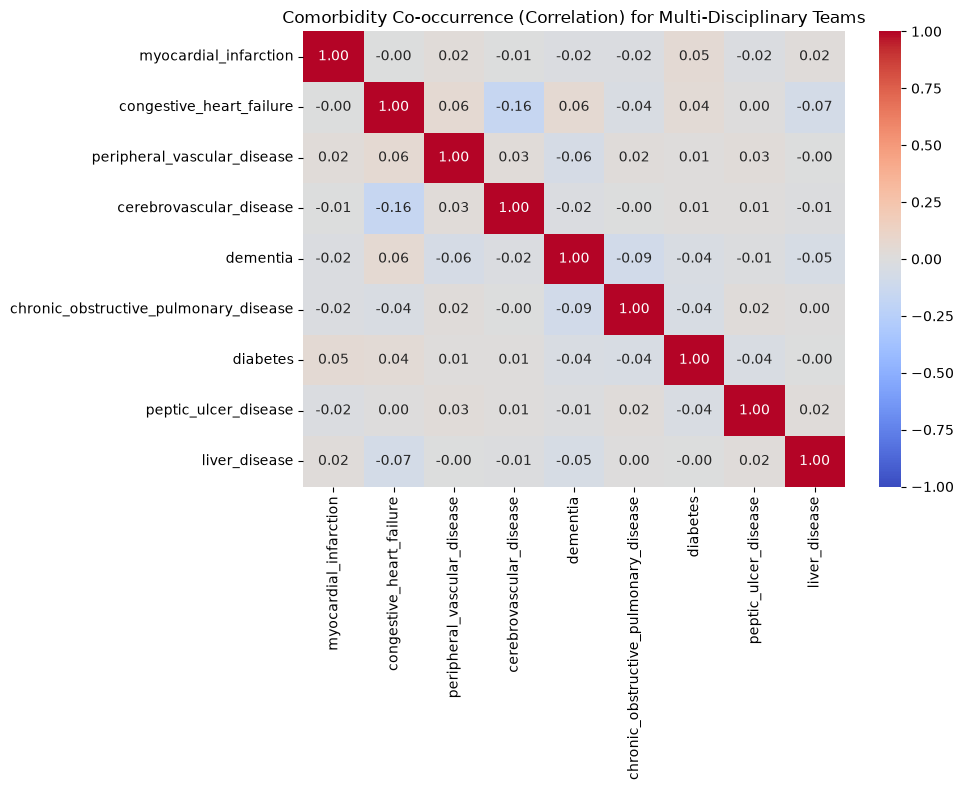

In [58]:
history_cols = [
    'myocardial_infarction', 'congestive_heart_failure', 'peripheral_vascular_disease', 
    'cerebrovascular_disease', 'dementia', 'chronic_obstructive_pulmonary_disease', 
    'diabetes', 'peptic_ulcer_disease', 'liver_disease'
]
comorbidity_matrix = dfPatientprofile[history_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(comorbidity_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Comorbidity Co-occurrence (Correlation) for Multi-Disciplinary Teams')
plt.tight_layout()
plt.show()

#### Q18 How should emergency triage protocols categorize abnormal temperature presentations based on the historical distribution of patient body temperatures upon admission?
Insight - This analysis defines the normal, expected distribution of admission body temperatures for heart failure patients, allowing triage nurses to easily spot statistical outliers that require immediate escalation.

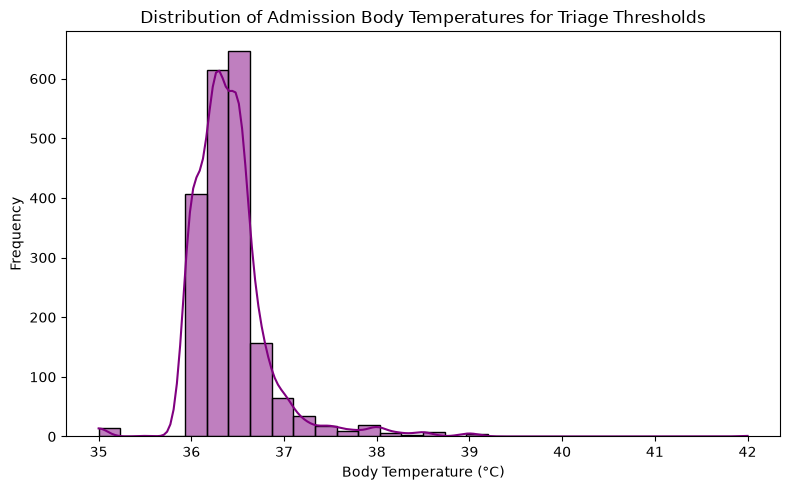

In [59]:
plt.figure(figsize=(8, 5))
sns.histplot(dfPatientprofile['body_temperature'].dropna(), bins=30, kde=True, color='purple')
plt.title('Distribution of Admission Body Temperatures for Triage Thresholds')
plt.xlabel('Body Temperature (°C)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

#### Q19 How does the cumulative burden of historical comorbidities differ between male and female patients, informing the intensity of gender-specific care pathways?
Insight - This analysis compares the total comorbidity load between male and female patients to determine if one demographic requires fundamentally more intensive, multi-disciplinary care pathways upon admission.

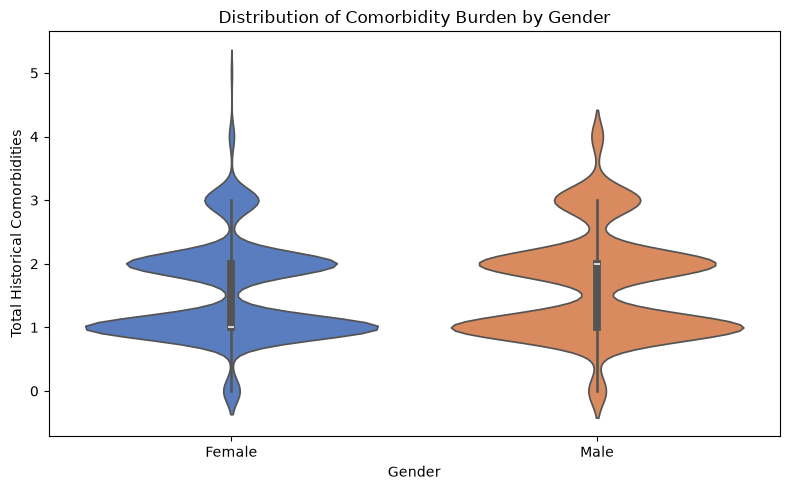

In [60]:
history_cols = [
    'myocardial_infarction', 'congestive_heart_failure', 'peripheral_vascular_disease', 
    'cerebrovascular_disease', 'dementia', 'chronic_obstructive_pulmonary_disease', 
    'diabetes', 'peptic_ulcer_disease', 'liver_disease'
]
dfPatientprofile['comorbidity_count'] = dfPatientprofile[history_cols].sum(axis=1)

plt.figure(figsize=(8, 5))
sns.violinplot(
    data=dfPatientprofile, 
    x='gender', 
    y='comorbidity_count', 
    palette='muted',
    hue='gender', legend=False
)
plt.title('Distribution of Comorbidity Burden by Gender')
plt.xlabel('Gender')
plt.ylabel('Total Historical Comorbidities')
plt.tight_layout()
plt.show()

The violin plot reveals not just the median comorbidity count, but the density and total spread of disease burden by gender. If one gender shows a significantly wider or higher distribution of comorbidities, clinical directors can adapt care pathways to ensure that admissions for that demographic automatically trigger broader system-level physiological reviews rather than strictly localized cardiac interventions.

#### Q20 Given a patient's historical comorbidities (e.g., liver disease or peptic ulcer disease), what alternative medication protocols should be recommended to minimize adverse drug events?
 Insight - This analysis isolates patients with specific organ vulnerabilities to audit their current prescriptions, highlighting commonly prescribed drugs that may require systemic dosage adjustments or substitution.

In [61]:
vuln_patients = dfPatientprofile[
    (dfPatientprofile['liver_disease'] == 1) | 
    (dfPatientprofile['peptic_ulcer_disease'] == 1)
]['inpatient_number']

vuln_prescriptions = dfPrescriptions[dfPrescriptions['inpatient_number'].isin(vuln_patients)]
print("Drugs prescribed to patients with liver/ulcer disease (flag for alternative protocol check):")
print(vuln_prescriptions['drug_name'].value_counts().head(10))

Drugs prescribed to patients with liver/ulcer disease (flag for alternative protocol check):
drug_name
Spironolactone tablet                               121
Furosemide injection                                115
Furosemide tablet                                   110
Digoxin tablet                                       66
Meglumine Adenosine Cyclophosphate for injection     63
Deslanoside injection                                58
Milrinone injection                                  55
Aspirin enteric-coated tablet                        46
Atorvastatin calcium tablet                          42
Metoprolol Succinate Sustained-release tablet        31
Name: count, dtype: int64


Result shows number of liver/ulcer patients and their current prescriptions

#### Q21 How should discharge medication regimens be optimized for patients with overlapping conditions, such as both congestive heart failure and diabetes, to reduce readmission risks?
Insight - This analysis maps the most frequently prescribed overlapping drug regimens for dual-diagnosis patients, providing a baseline to standardize and simplify discharge medication bundles.

In [62]:
# Analyze current regimens for patients with both CHF and Diabetes
chf_diabetic_patients = dfPatientprofile[
    (dfPatientprofile['congestive_heart_failure'] == 1) & 
    (dfPatientprofile['diabetes'] == 1)
]['inpatient_number']

chf_diabetic_rx = dfPrescriptions[dfPrescriptions['inpatient_number'].isin(chf_diabetic_patients)]
print("Most common overlapping medications for CHF + Diabetic patients:")
print(chf_diabetic_rx['drug_name'].value_counts().head(10))

Most common overlapping medications for CHF + Diabetic patients:
drug_name
Furosemide injection                                406
Spironolactone tablet                               398
Furosemide tablet                                   360
Aspirin enteric-coated tablet                       247
Atorvastatin calcium tablet                         226
Meglumine Adenosine Cyclophosphate for injection    220
Deslanoside injection                               220
Digoxin tablet                                      212
Milrinone injection                                 166
Metoprolol Succinate Sustained-release tablet       129
Name: count, dtype: int64


Understanding the exact composition of medications commonly issued to CHF/Diabetic patients allows the hospital to create standardized "discharge bundles." By knowing which cardiovascular and endocrine drugs are most frequently combined, clinical educators can design specific, pre-printed medication schedules for these patients, optimizing for drug-drug interactions and vastly improving patient adherence at home.

#### Q22 Based on the cumulative count of severe comorbidities (e.g., dementia, COPD, cerebrovascular disease), what should be the mandated timeline for a patient's post-discharge outpatient follow-up
Insight - This analysis quantifies the overall comorbidity burden per patient to dynamically assign safe and appropriate outpatient follow-up intervals, rather than relying on a generalized timeline.

In [63]:
# Assign follow-up timelines based on cumulative severe comorbidities
history_cols = [
    'myocardial_infarction', 'congestive_heart_failure', 
    'peripheral_vascular_disease', 'cerebrovascular_disease', 
    'dementia', 'chronic_obstructive_pulmonary_disease', 
    'diabetes', 'peptic_ulcer_disease', 'liver_disease'
]
dfPatientprofile['comorbidity_count'] = dfPatientprofile[history_cols].sum(axis=1)

# Define prescriptive mapping
def assign_follow_up(count):
    if count >= 4: return '1-Week (High Risk)'
    elif count >= 2: return '2-Week (Moderate Risk)'
    else: return '4-Week (Standard)'

dfPatientprofile['follow_up_timeline'] = dfPatientprofile['comorbidity_count'].apply(assign_follow_up)
print("Recommended Follow-Up Timelines:")
print(dfPatientprofile['follow_up_timeline'].value_counts())

Recommended Follow-Up Timelines:
follow_up_timeline
4-Week (Standard)         1028
2-Week (Moderate Risk)     953
1-Week (High Risk)          27
Name: count, dtype: int64


Categorizing patients by their cumulative comorbidity score quantifies the operational demand for different outpatient scheduling tracks. The resulting text table provides clinic administrators with the exact patient volume metrics needed to block off early appointment slots (e.g., within 7 days) specifically for the high-risk cohort

### Q23 Which demographic profiles (based on gender, BMI, and historical comorbidities) should be targeted with highly specialized, condition-specific discharge education programs?
Insight - This analysis uses a crosstab to segment the patient population by overlapping demographic and clinical risk factors, providing a matrix to pinpoint target audiences for specialized education programs.

In [64]:
# Create BMI categories
dfPatientprofile['BMI_Category'] = pd.cut(dfPatientprofile['bmi'], bins=[0, 18.5, 24.9, 29.9, 100], labels=['Underweight', 'Normal', 'Overweight', 'Obese'])

# Generate a crosstab mapping Gender and Diabetes status against BMI Categories
education_matrix = pd.crosstab(
    index=[dfPatientprofile['gender'], dfPatientprofile['diabetes']], 
    columns=dfPatientprofile['BMI_Category'],
    margins=True,
    margins_name="Total"
)

# Rename index for clarity
education_matrix.index.names = ['Gender', 'Diabetes (1=Yes, 0=No)']

print("Target Demographics for Specialized Discharge Education (Patient Counts):")
print("-" * 80)
print(education_matrix)

Target Demographics for Specialized Discharge Education (Patient Counts):
--------------------------------------------------------------------------------
BMI_Category                   Underweight  Normal  Overweight  Obese  Total
Gender Diabetes (1=Yes, 0=No)                                               
Female 0                               244     492         110     24    870
       1                                70     165          42     12    289
Male   0                               158     409          76     24    667
       1                                36      97          35      7    175
Total                                  508    1163         263     67   2001


The crosstab matrix breaks down specific cohorts sharing multiple demographic and clinical risks. By viewing the exact patient counts in intersecting cells (such as Obese Diabetic Males), health educators can allocate their limited time efficiently, deploying highly-tailored interactive education sessions directly to the largest demographic clusters.

#### Q24 Count of patients who should be referred to a nephrologist based on kidney function?

In [65]:
# Step 1: Define a function that maps a GFR value to a recommended renal action.
# Missing GFR values are flagged.
def renal_action(gfr):
    if pd.isna(gfr):
        return 'Insufficient data - test GFR'
    elif gfr < 30:
        return 'Refer to Nephrologist (urgent)'
    elif gfr < 60:
        return 'Monitor renal function closely'
    else:
        return 'No referral needed'

# Step 2: Apply the function to every patient's GFR value
dfPatientprofile['renal_recommendation'] = dfPatientprofile['glomerular_filtration_rate'].apply(renal_action)

# Step 3: Count patients per recommended action
dfPatientprofile['renal_recommendation'].value_counts()

renal_recommendation
No referral needed                1059
Monitor renal function closely     634
Refer to Nephrologist (urgent)     252
Insufficient data - test GFR        63
Name: count, dtype: int64

Roughly 44% of patients need at least monitoring or urgent referral for renal function (634 + 252 of 2,008), showing kidney impairment is common in this cohort, not an edge case.

#### Q25 Which ward should a newly admitted patient be assigned to and cross check the count with actual counts.

In [66]:
# Step 1: Flag patients as needing ICU if they show severe heart failure/shock signs

dfPatientprofile['ward_recommendation'] = np.where(
    (dfPatientprofile['killip_grade'] >= 3) | (dfPatientprofile['nyha_cardiac_function_classification'] == 4),
    'ICU', 'General Cardiology Ward'
)

print(dfPatientprofile['ward_recommendation'].value_counts())

ward_recommendation
General Cardiology Ward    1134
ICU                         874
Name: count, dtype: int64


The severity rule flags 874 patients (44%) for ICU, but only 10 of them were actually admitted there — most high-severity patients were managed in the general Cardiology ward instead.

#### Q26 Should a patient be started on supplemental oxygen therapy at admission?

In [67]:
# Step 1: Recommend oxygen therapy if either oxygen saturation below 92% or respiration rate above 24 breaths/min
dfPatientprofile['oxygen_recommendation'] = np.where(
    (dfPatientprofile['oxygen_saturation'] < 92) | (dfPatientprofile['respiration'] > 24),
    'Start Oxygen Therapy', 'Sufficient Oxygen'
)

print(dfPatientprofile['oxygen_recommendation'].value_counts())

oxygen_recommendation
Sufficient Oxygen       1891
Start Oxygen Therapy     117
Name: count, dtype: int64


Only about 6% of patients (117 of 2,008) meet the threshold for supplemental oxygen, indicating most patients maintain adequate saturation and respiration at admission.

#### Q27 Should a patient be discharged home or to a healthcare facility?

In [68]:
# Step 1 & 2: Recommend facility-based discharge if the patient's consciousness is not
# 'Clear' or their Glasgow Coma Scale (GCS) score is below the normal maximum of 15
dfPatientprofile['discharge_recommendation'] = np.where(
    (dfPatientprofile['consciousness'] != 'Clear') | (dfPatientprofile['gcs'] < 15),
    'Recommend Healthcare Facility', 'Recommend Home Discharge'
)

print(dfPatientprofile['discharge_recommendation'].value_counts())

discharge_recommendation
Recommend Home Discharge         1951
Recommend Healthcare Facility      57
Name: count, dtype: int64


Nearly all patients (97%) are recommended for home discharge, with only 57 flagged for facility care based on impaired consciousness or low GCS.

#### Q28 How can beds be optimally allocated across admission wards based on the need (if we assume total beds as 100)?

In [69]:
# Step 1: Calculate patient volume and average severity (Killip grade) per ward.
ward_stats = dfPatientprofile.groupby('admission_ward').agg(
    patient_count=('inpatient_number', 'count'),
    avg_severity=('killip_grade', 'mean')
).dropna()

# Step 2: Combine volume and severity into a single "demand weight" per ward
ward_stats['demand_weight'] = ward_stats['patient_count'] * ward_stats['avg_severity']
ward_stats

,patient_count,avg_severity,demand_weight
admission_ward,,,
Cardiology,1547,1.994182,3085.0
GeneralWard,265,2.018868,535.0
ICU,15,2.400000,36.0
Others,181,1.906077,345.0


In [70]:
# Step 3: optimization

TOTAL_BEDS = 100  
n = len(ward_stats)
demand = ward_stats['demand_weight'].values
demand_share = demand / demand.sum()

# Store and display the recommended bed allocation per ward
ward_stats['recommended_beds'] = np.round(demand_share*100).astype(int)

ward_stats[['patient_count', 'avg_severity', 'recommended_beds']]

,patient_count,avg_severity,recommended_beds
admission_ward,,,
Cardiology,1547,1.994182,77
GeneralWard,265,2.018868,13
ICU,15,2.400000,1
Others,181,1.906077,9


Cardiology absorbs about 77% of the 100 allocated beds despite having the lowest average severity score — its sheer patient volume (1,547) drives demand far more than acuity does.

#### Q29 What tiered care pathway should each patient be assigned to, based on a composite multi-factor risk score?

In [71]:
# Step 1: Define one point-scoring function per risk factor.

def nyha_points(v):
    if pd.isna(v): return 0
    return {1: 0, 2: 1, 3: 2, 4: 3}.get(int(v), 0)

def killip_points(v):
    if pd.isna(v): return 0
    return {1: 0, 2: 1, 3: 2, 4: 3}.get(int(v), 0)

def lvef_points(v):
    if pd.isna(v): return 1  # unknown LVEF treated as mild risk, not zero
    if v < 30: return 3
    elif v < 40: return 2
    elif v < 50: return 1
    else: return 0

def gfr_points(v):
    if pd.isna(v): return 1
    if v < 30: return 3
    elif v < 60: return 2
    elif v < 90: return 1
    else: return 0

def cci_points(v):
    if pd.isna(v): return 0
    if v >= 5: return 3
    elif v >= 3: return 2
    elif v >= 1: return 1
    else: return 0

# Step 2: Apply each scoring function to its corresponding column, then sum all into one composite risk score (range 0-15)
dfPatientprofile['risk_score'] = (
    dfPatientprofile['nyha_cardiac_function_classification'].apply(nyha_points) +
    dfPatientprofile['killip_grade'].apply(killip_points) +
    dfPatientprofile['lvef'].apply(lvef_points) +
    dfPatientprofile['glomerular_filtration_rate'].apply(gfr_points) +
    dfPatientprofile['cci_score'].apply(cci_points)
)

dfPatientprofile['risk_score'].describe()

count    2008.000000
mean        6.571215
std         1.852000
min         2.000000
25%         5.000000
50%         6.000000
75%         8.000000
max        12.000000
Name: risk_score, dtype: float64

In [72]:
# Step 3: Bin the composite risk score into three tiers 
def care_pathway(score):
    if score >= 9:
        return 'Intensive Case Management (weekly nurse contact + specialist review)'
    elif score >= 5:
        return 'Enhanced Monitoring (biweekly check-ins)'
    else:
        return 'Standard Care (routine follow-up)'

dfPatientprofile['care_pathway_recommendation'] = dfPatientprofile['risk_score'].apply(care_pathway)

# Step 4: Review how many patients fall into each care pathway
dfPatientprofile['care_pathway_recommendation'].value_counts()

care_pathway_recommendation
Enhanced Monitoring (biweekly check-ins)                                1424
Intensive Case Management (weekly nurse contact + specialist review)     310
Standard Care (routine follow-up)                                        274
Name: count, dtype: int64

The majority of patients (71%) fall into "Enhanced Monitoring," with only 15% requiring Intensive Case Management, suggesting most patients carry moderate — not extreme — combined risk.

#### Q30 For patients already on a diuretic, should the dose be continued, reduced, or held based on renal function and potassium?

In [73]:
# Step 1: Identify the diuretics.
diuretic_keywords = ['Furosemide', 'Hydrochlorothiazide', 'Spironolactone']
dfPrescriptions['is_diuretic'] = dfPrescriptions['drug_name'].str.contains(
    '|'.join(diuretic_keywords), case=False, na=False
)

# Step 2: Get the unique list of patients who received at least one diuretic prescription
diuretic_patients = dfPrescriptions.loc[dfPrescriptions['is_diuretic'], 'inpatient_number'].unique()
dfPatientprofile['on_diuretic'] = dfPatientprofile['inpatient_number'].isin(diuretic_patients)

print(f"Patients on a diuretic: {dfPatientprofile['on_diuretic'].sum()} of {len(dfPatientprofile)}")

Patients on a diuretic: 1974 of 2008


In [74]:
# Step 3: Give Recommendation
def diuretic_action(row):
    if not row['on_diuretic']:
        return 'Not applicable (no diuretic prescribed)'
    gfr, k = row['glomerular_filtration_rate'], row['potassium']
    if pd.isna(gfr) or pd.isna(k):
        return 'Recheck renal function / potassium before continuing'
    # Nested logic: renal function AND potassium interact
    if gfr < 30 and k > 5.0:
        return 'Hold diuretic - risk of hyperkalemia with severe renal impairment'
    elif gfr < 30:
        return 'Reduce dose - severe renal impairment'
    elif k > 5.0:
        return 'Hold potassium-sparing diuretic - monitor potassium'
    elif k < 3.5:
        return 'Continue diuretic + add potassium supplementation'
    else:
        return 'Continue current diuretic dose'

# Execute the function
dfPatientprofile['diuretic_recommendation'] = dfPatientprofile.apply(diuretic_action, axis=1)

# Step 4: Summarize how many patients fall into each recommended action
dfPatientprofile['diuretic_recommendation'].value_counts()

diuretic_recommendation
Continue current diuretic dose                                       1156
Continue diuretic + add potassium supplementation                     413
Reduce dose - severe renal impairment                                 180
Hold potassium-sparing diuretic - monitor potassium                    89
Hold diuretic - risk of hyperkalemia with severe renal impairment      70
Recheck renal function / potassium before continuing                   66
Not applicable (no diuretic prescribed)                                34
Name: count, dtype: int64

98% of patients are on a diuretic, and while most (1,156) can safely continue their current dose, a meaningful 250 patients (180+70) need a reduced or held dose due to renal impairment or hyperkalemia risk.

---
# End of Prescriptive Analysis

In [75]:
print(dfPatientprofile["destinationdischarge"].value_counts(dropna=False))

destinationdischarge
Home                  1344
HealthcareFacility     438
Unknown                212
Died                    14
Name: count, dtype: int64


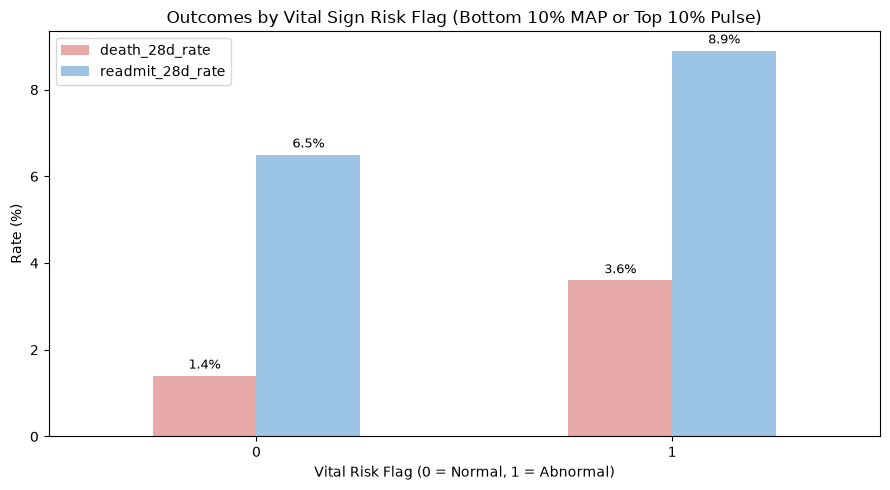

,patient_count,death_28d_rate,readmit_28d_rate
vital_risk_flag,,,
0,1615,1.4,6.5
1,393,3.6,8.9


In [76]:
#  Do abnormal vital signs at admission predict worse outcomes, and should these patients get closer monitoring? 

map_threshold = dfPatientprofile["map_value"].quantile(0.10)
pulse_threshold = dfPatientprofile["pulse"].quantile(0.90)

dfPatientprofile["vital_risk_flag"] = (
    (dfPatientprofile["map_value"] <= map_threshold) |
    (dfPatientprofile["pulse"] >= pulse_threshold)
).astype(int)

vital_outcomes = dfPatientprofile.groupby("vital_risk_flag").agg(
    patient_count=("inpatient_number", "count"),
    death_28d_rate=("death_within_28_days", "mean"),
    readmit_28d_rate=("re_admission_within_28_days", "mean")
).round(3)
vital_outcomes[["death_28d_rate", "readmit_28d_rate"]] *= 100

ax = vital_outcomes[["death_28d_rate", "readmit_28d_rate"]].plot(kind="bar", figsize=(9,5), color=["#E8A9A9", "#9CC4E4"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)
plt.title("Outcomes by Vital Sign Risk Flag (Bottom 10% MAP or Top 10% Pulse)")
plt.xlabel("Vital Risk Flag (0 = Normal, 1 = Abnormal)")
plt.ylabel("Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# print in table form
vital_outcomes

#### Insights : Patients with critically low MAP (bottom 10%) or high pulse (top 10%) at admission have a 3.6% 28-day death rate — 2.6x higher than others (1.4%) — and higher readmission (8.9% vs 6.5%). Recommend closer vital-sign monitoring in the first 24 hours for this group.